## Estimación de ráiz por Monte Carlo

Se evalua la $\sqrt{2}$ a través del método de Monte Carlo

In [2]:
"""
Estimación de sqrt(2) por Simulación de Monte Carlo
=====================================================
Objetivo:
    Estimar sqrt(2) mediante el lanzamiento de dardos aleatorios y determinar
    cuántos lanzamientos son necesarios para garantizar una precisión de 1e-3
    con probabilidad de error menor a 1e-2.

Método:
    Se genera X ~ U(0,2) y se define éxito si X^2 <= 2.
    p = P(éxito) = sqrt(2)/2, por lo tanto sqrt(2) = 2p.
    El estimador es theta_hat = 2 * (proporción de éxitos).

Criterios para tamaño muestral:
    - Desigualdad de Hoeffding (garantía estricta)
    - Desigualdad de Chebyshev (cota conservadora)
    - Aproximación normal (TCL)

Se generan gráficas de convergencia, error, comparación de tamaños,
diagrama de flujo y verificación empírica de la cota de Hoeffding.
"""

import numpy as np
import matplotlib.pyplot as plt
import math
import time

# ============================================================
# Configuración general para gráficas
# ============================================================
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# ============================================================
# Funciones auxiliares
# ============================================================
def estimar_sqrt2(n, semilla=None):
    """
    Estima sqrt(2) mediante Monte Carlo con n lanzamientos.
    Éxito: X^2 <= 2, donde X ~ U(0,2).
    Retorna: theta_hat, p_hat, X, exitos
    """
    if semilla is not None:
        rng = np.random.default_rng(semilla)
    else:
        rng = np.random.default_rng()
    X = rng.uniform(0, 2, size=n)
    exitos = (X**2 <= 2)
    p_hat = np.mean(exitos)
    theta_hat = 2.0 * p_hat
    return theta_hat, p_hat, X, exitos

def tamano_muestral_hoeffding(epsilon=5e-4, delta=1e-2):
    """
    Desigualdad de Hoeffding:
    P(|p_hat - p| >= epsilon) <= 2*exp(-2*n*epsilon^2) < delta
    => n > ln(2/delta) / (2*epsilon^2)
    """
    n = math.ceil(math.log(2.0/delta) / (2.0 * epsilon**2))
    return n

def tamano_muestral_chebyshev(epsilon=5e-4, delta=1e-2):
    """
    Desigualdad de Chebyshev:
    Var(p_hat) <= 1/(4n)
    P(|p_hat - p| >= epsilon) <= 1/(4 n epsilon^2) < delta
    """
    n = math.ceil(1.0 / (4.0 * delta * epsilon**2))
    return n

def tamano_muestral_aprox_normal(epsilon=5e-4, alpha=0.01):
    """
    Aproximación normal con z_{1-alpha/2}.
    n = z^2 * p(1-p) / epsilon^2
    """
    p = math.sqrt(2)/2
    z = 2.576  # cuantil 0.995
    var_p = p * (1-p)
    n = math.ceil((z**2 * var_p) / epsilon**2)
    return n

# ============================================================
# Parámetros del problema
# ============================================================
epsilon = 5e-4   # error máximo en p (equivale a 1e-3 en sqrt(2))
delta = 1e-2     # probabilidad máxima de exceder ese error
semilla = 2026

### Cálculo del número de muestras

Se calcula el número máximo de muestras a sacar para poder obtener un error mínimo de $5e^{-5}$, a través de los métodos:
* Heoffding
* Chebyshev
* Normal

In [3]:
# ============================================================
# 1. Cálculo de tamaños muestrales teóricos
# ============================================================
n_hoeffding = tamano_muestral_hoeffding(epsilon, delta)
n_chebyshev = tamano_muestral_chebyshev(epsilon, delta)
n_normal = tamano_muestral_aprox_normal(epsilon, alpha=delta)

print("=" * 70)
print("TAMAÑO MUESTRAL REQUERIDO PARA GARANTIZAR")
print("P(|error| > 1e-3 en sqrt(2)) < 1e-2")
print("=" * 70)
print(f"Desigualdad de Hoeffding : n >= {n_hoeffding:,}")
print(f"Desigualdad de Chebyshev  : n >= {n_chebyshev:,}")
print(f"Aproximación normal (TCL) : n >= {n_normal:,}")
print("=" * 70)

TAMAÑO MUESTRAL REQUERIDO PARA GARANTIZAR
P(|error| > 1e-3 en sqrt(2)) < 1e-2
Desigualdad de Hoeffding : n >= 10,596,635
Desigualdad de Chebyshev  : n >= 100,000,000
Aproximación normal (TCL) : n >= 5,497,257


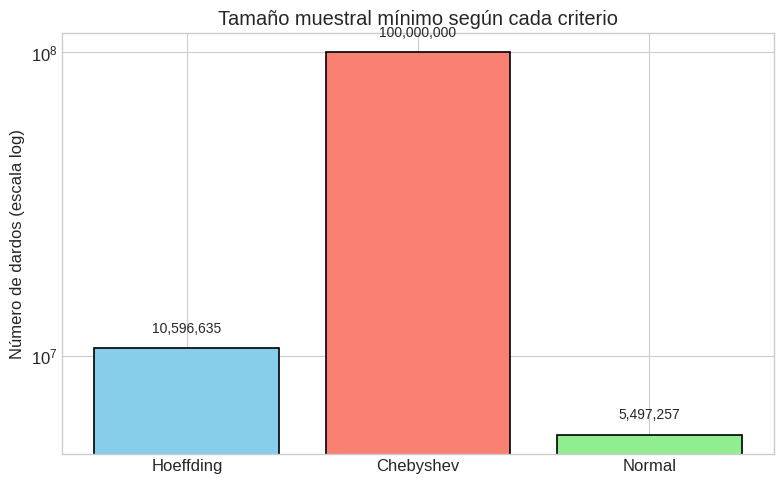

In [4]:
# ============================================================
# 2. Gráfica comparativa de tamaños muestrales
# ============================================================
metodos = ['Hoeffding', 'Chebyshev', 'Normal']
tamanos = [n_hoeffding, n_chebyshev, n_normal]
colores = ['skyblue', 'salmon', 'lightgreen']

plt.figure(figsize=(8,5))
bars = plt.bar(metodos, tamanos, color=colores, edgecolor='black', linewidth=1.2)
plt.yscale('log')  # escala logarítmica por la gran diferencia
plt.ylabel('Número de dardos (escala log)')
plt.title('Tamaño muestral mínimo según cada criterio')
for bar, val in zip(bars, tamanos):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.1,
             f'{val:,}', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('comparacion_tamanos.png', dpi=150)
plt.show()

### Diagrama de flujo del experimento

<>:33: SyntaxWarning: invalid escape sequence '\s'
<>:33: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2915/2231379233.py:33: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Diagrama de flujo: Estimación de $\sqrt{2}$ por Monte Carlo', fontsize=14)


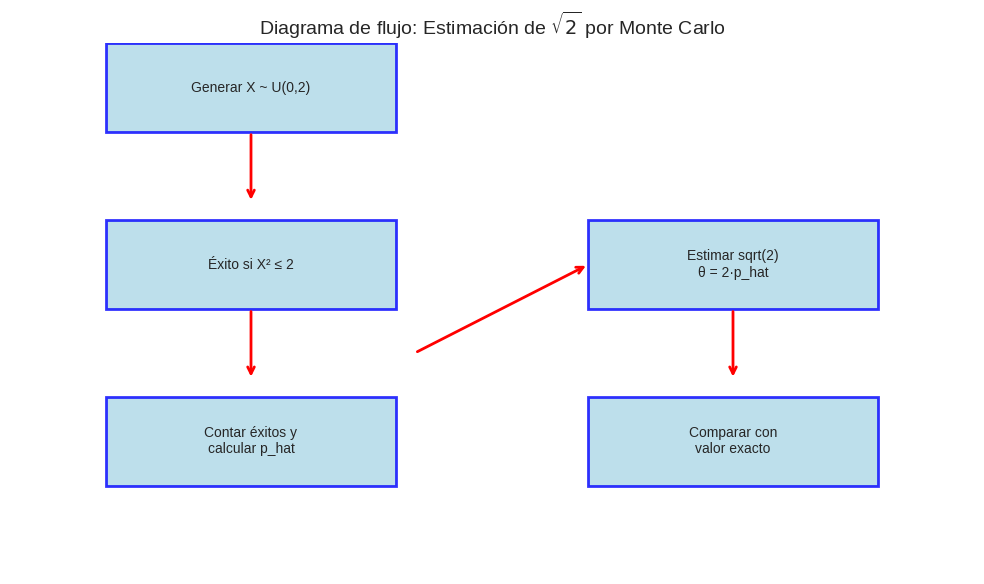

In [5]:
# ============================================================
# 3. Diagrama de flujo del experimento
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')

cajas = [
    (1, 5, 3, 1, 'Generar X ~ U(0,2)'),
    (1, 3, 3, 1, 'Éxito si X² ≤ 2'),
    (1, 1, 3, 1, 'Contar éxitos y\ncalcular p_hat'),
    (6, 3, 3, 1, 'Estimar sqrt(2)\nθ = 2·p_hat'),
    (6, 1, 3, 1, 'Comparar con\nvalor exacto')
]

for (x, y, w, h, texto) in cajas:
    rect = plt.Rectangle((x, y), w, h, facecolor='lightblue', 
                          edgecolor='blue', linewidth=2, alpha=0.8)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, texto, ha='center', va='center', fontsize=10)

flechas = [
    (2.5, 5, 2.5, 4.2),
    (2.5, 3, 2.5, 2.2),
    (4.2, 2.5, 6, 3.5),
    (7.5, 3, 7.5, 2.2),
]
for (x1, y1, x2, y2) in flechas:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', lw=2, color='red'))

plt.title('Diagrama de flujo: Estimación de $\sqrt{2}$ por Monte Carlo', fontsize=14)
plt.tight_layout()
plt.savefig('diagrama_flujo.png', dpi=150)
plt.show()

### Simulación

In [6]:
# ============================================================
# 4. Simulación con n = 1,000,000 (un millón de dardos)
# ============================================================
n_sim = 1_000_000
t_inicio = time.time()
theta_hat, p_hat, X_sim, exitos_sim = estimar_sqrt2(n_sim, semilla)
t_fin = time.time()
error_abs = abs(theta_hat - math.sqrt(2))

print("\n--- Simulación con n =", f"{n_sim:,}", "dardos ---")
print(f"Proporción de éxitos p_hat    = {p_hat:.6f}")
print(f"Estimación de sqrt(2)         = {theta_hat:.6f}")
print(f"Valor exacto de sqrt(2)       = {math.sqrt(2):.6f}")
print(f"Error absoluto                = {error_abs:.2e}")
print(f"Tiempo de ejecución           = {t_fin - t_inicio:.3f} s")

if error_abs <= 1e-3:
    print("\nCon n =", f"{n_sim:,}", "el error es menor o igual a 1e-3.")
else:
    print("\nCon n =", f"{n_sim:,}", "el error es mayor que 1e-3 (esperado, pues n es menor que el requerido por Hoeffding).")


--- Simulación con n = 1,000,000 dardos ---
Proporción de éxitos p_hat    = 0.707505
Estimación de sqrt(2)         = 1.415010
Valor exacto de sqrt(2)       = 1.414214
Error absoluto                = 7.96e-04
Tiempo de ejecución           = 0.016 s

Con n = 1,000,000 el error es menor o igual a 1e-3.


### Convergencia del valor estimado

<>:13: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2915/2670769766.py:13: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(n_values, theta_acum, 'b-', linewidth=1.5, label='$\hat{\\theta}_n$')
/tmp/ipykernel_2915/2670769766.py:17: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel('Estimación de $\sqrt{2}$')


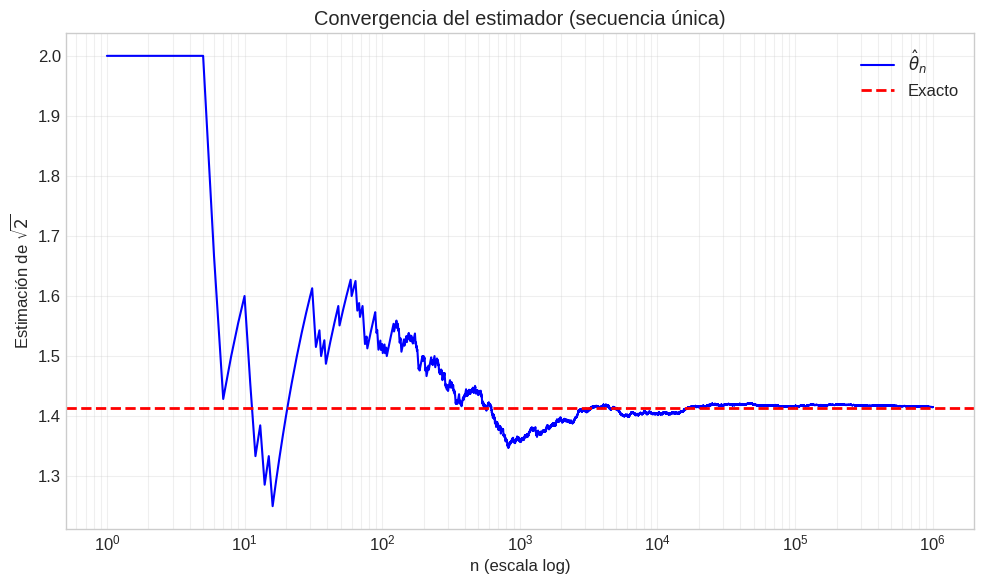

In [7]:
# ============================================================
# 5. Convergencia del estimador (secuencia única acumulativa)
# ============================================================
# Generamos una secuencia larga de 1,000,000 uniformes y acumulamos
rng_conv = np.random.default_rng(semilla)
X_largo = rng_conv.uniform(0, 2, size=1_000_000)
exitos_largo = (X_largo**2 <= 2)
acumulado = np.cumsum(exitos_largo)
n_values = np.arange(1, 1_000_001)
theta_acum = 2.0 * acumulado / n_values

plt.figure(figsize=(10,6))
plt.plot(n_values, theta_acum, 'b-', linewidth=1.5, label='$\hat{\\theta}_n$')
plt.axhline(y=math.sqrt(2), color='red', linestyle='--', linewidth=2, label='Exacto')
plt.xscale('log')
plt.xlabel('n (escala log)')
plt.ylabel('Estimación de $\sqrt{2}$')
plt.title('Convergencia del estimador (secuencia única)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('convergencia.png', dpi=150)
plt.show()

### Error del estimador

Evaluamos el error de la simulación para evaluar la $\sqrt{2}$, en escala logaritmica.

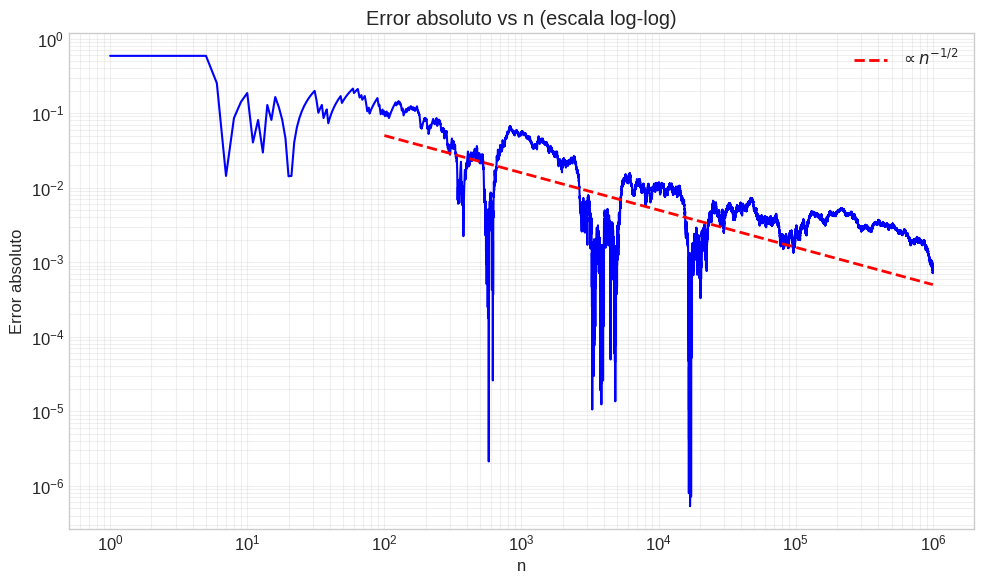

In [8]:
# ============================================================
# 6. Error absoluto vs n en escala log-log
# ============================================================
error_acum = np.abs(theta_acum - math.sqrt(2))

plt.figure(figsize=(10,6))
plt.loglog(n_values, error_acum, 'b-', linewidth=1.5)
plt.xlabel('n')
plt.ylabel('Error absoluto')
plt.title('Error absoluto vs n (escala log-log)')
plt.grid(True, which='both', alpha=0.3)

# Línea de referencia: error ~ 1/sqrt(n)
n_ref = np.array([1e2, 1e6])
error_ref = 0.5 / np.sqrt(n_ref)  # factor aproximado
plt.loglog(n_ref, error_ref, 'r--', linewidth=2, label=r'$\propto n^{-1/2}$')
plt.legend()
plt.tight_layout()
plt.savefig('error_vs_n.png', dpi=150)
plt.show()

### Histograma de las réplicas

<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2915/743469152.py:18: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Estimación de $\sqrt{2}$')



Generando 500 réplicas con n = 10000 cada una...
Tiempo total: 0.06 s


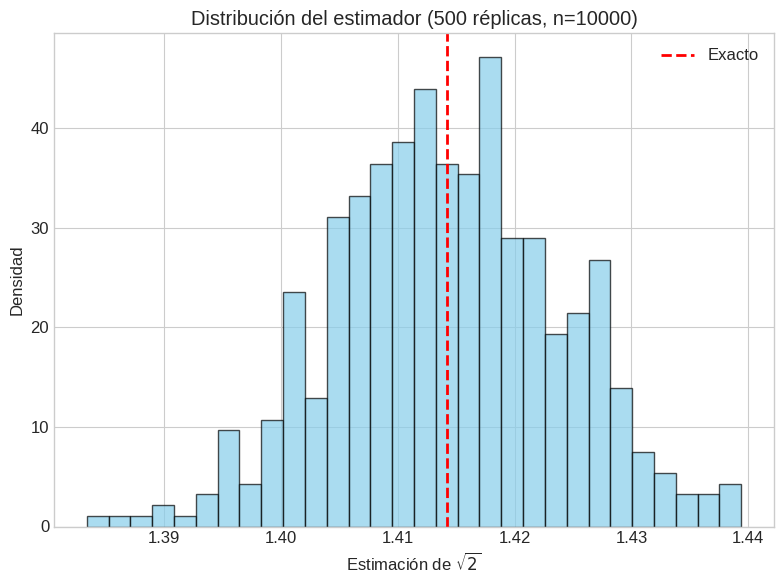

Media de las réplicas: 1.414155
Desviación estándar: 0.009572


In [9]:
# ============================================================
# 7. Histograma de estimaciones en réplicas
# ============================================================
n_rep = 10_000
R = 500
replicas = np.zeros(R)
print(f"\nGenerando {R} réplicas con n = {n_rep} cada una...")
t_inicio_rep = time.time()
for r in range(R):
    theta_r, _, _, _ = estimar_sqrt2(n_rep, semilla + r)
    replicas[r] = theta_r
t_fin_rep = time.time()
print(f"Tiempo total: {t_fin_rep - t_inicio_rep:.2f} s")

plt.figure(figsize=(8,6))
plt.hist(replicas, bins=30, density=True, alpha=0.7, color='skyblue', edgecolor='black')
plt.axvline(x=math.sqrt(2), color='red', linestyle='--', linewidth=2, label='Exacto')
plt.xlabel('Estimación de $\sqrt{2}$')
plt.ylabel('Densidad')
plt.title(f'Distribución del estimador ({R} réplicas, n={n_rep})')
plt.legend()
plt.tight_layout()
plt.savefig('histograma_replicas.png', dpi=150)
plt.show()

print(f"Media de las réplicas: {np.mean(replicas):.6f}")
print(f"Desviación estándar: {np.std(replicas, ddof=1):.6f}")

### Cota de Hoeffding


--- Verificación empírica de la cota de Hoeffding ---
Se usarán 200 réplicas para cada tamaño de muestra.
Esto puede tardar unos minutos...
n =     10,000: Probabilidad empírica = 0.930000
n =     50,000: Probabilidad empírica = 0.815000
n =    100,000: Probabilidad empírica = 0.730000
n =    500,000: Probabilidad empírica = 0.450000
n =  1,000,000: Probabilidad empírica = 0.290000


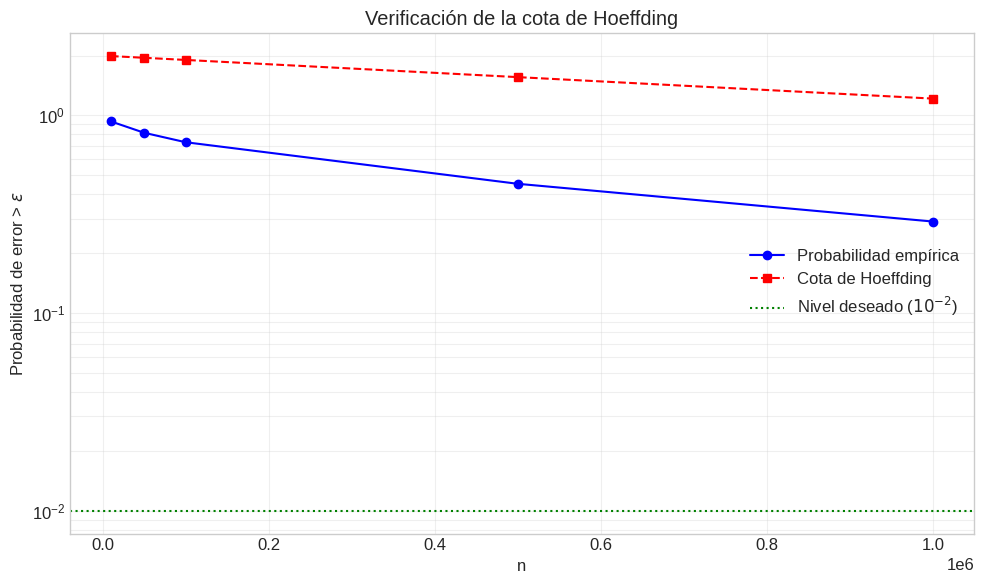

In [10]:
# ============================================================
# 8. Verificación empírica de la cota de Hoeffding
# ============================================================
epsilon_p = 5e-4  # error en p
delta_obj = 1e-2

n_pruebas = [10_000, 50_000, 100_000, 500_000, 1_000_000]
R_prueba = 200  # número de réplicas para estimar la probabilidad

print("\n--- Verificación empírica de la cota de Hoeffding ---")
print(f"Se usarán {R_prueba} réplicas para cada tamaño de muestra.")
print("Esto puede tardar unos minutos...")

prob_empirica = []
for n in n_pruebas:
    errores = []
    for r in range(R_prueba):
        _, p_hat_r, _, _ = estimar_sqrt2(n, semilla + 1000 + r)
        err = abs(p_hat_r - math.sqrt(2)/2)
        errores.append(err)
    prob = np.mean(np.array(errores) > epsilon_p)
    prob_empirica.append(prob)
    print(f"n = {n:>10,}: Probabilidad empírica = {prob:.6f}")

# Cota de Hoeffding
def cota_hoeffding(n, eps):
    return 2 * np.exp(-2 * n * eps**2)

cota_vals = [cota_hoeffding(n, epsilon_p) for n in n_pruebas]

plt.figure(figsize=(10,6))
plt.semilogy(n_pruebas, prob_empirica, 'o-', label='Probabilidad empírica', color='blue')
plt.semilogy(n_pruebas, cota_vals, 's--', label='Cota de Hoeffding', color='red')
plt.axhline(y=delta_obj, color='green', linestyle=':', label='Nivel deseado ($10^{-2}$)')
plt.xlabel('n')
plt.ylabel('Probabilidad de error > $\\varepsilon$')
plt.title('Verificación de la cota de Hoeffding')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('verificacion_hoeffding.png', dpi=150)
plt.show()

## Conclusiones

In [11]:
# ============================================================
# 9. Conclusiones finales
# ============================================================
print("\n" + "=" * 70)
print("CONCLUSIONES")
print("=" * 70)
print(f"1. La estimación Monte Carlo de sqrt(2) converge a razón O(1/sqrt(n)).")
print(f"2. Con n = 1,000,000 se obtiene un error típico del orden de {error_acum[-1]:.2e}.")
print(f"3. Para garantizar P(|error| > 1e-3) < 1e-2, la cota de Hoeffding exige n >= {n_hoeffding:,} dardos.")
print(f"4. La aproximación normal da un valor menor ({n_normal:,}), pero sin garantía estricta para n finito.")
print(f"5. Las simulaciones empíricas muestran que la probabilidad real de exceder el error es mucho menor que la cota teórica para n moderados.")
print("=" * 70)


CONCLUSIONES
1. La estimación Monte Carlo de sqrt(2) converge a razón O(1/sqrt(n)).
2. Con n = 1,000,000 se obtiene un error típico del orden de 7.96e-04.
3. Para garantizar P(|error| > 1e-3) < 1e-2, la cota de Hoeffding exige n >= 10,596,635 dardos.
4. La aproximación normal da un valor menor (5,497,257), pero sin garantía estricta para n finito.
5. Las simulaciones empíricas muestran que la probabilidad real de exceder el error es mucho menor que la cota teórica para n moderados.
